In [1]:
!pip install importlib_resources #INSTALAMOS COMPLEMENTO PARA ACCEDER A RECURSOS DEL DATASET

ERROR: Invalid requirement: '#INSTALAMOS'

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

In [3]:
ds= tfds.load('oxford_iiit_pet')

In [4]:
NOMBRES=['gato','perro']
print(NOMBRES)

['gato', 'perro']


In [5]:
def preparar(d):
  img= tf.image.resize(d['image'], (128,128))/255 #Modificamos el tamaño de la imagen y la normalizamos
  return img, d['species'] #Retornamos la imagen y su respectiva etiqueta

In [6]:
train= ds['train'].map(preparar).shuffle(1000).batch(32)
test= ds['test'].map(preparar).shuffle(1000).batch(32)

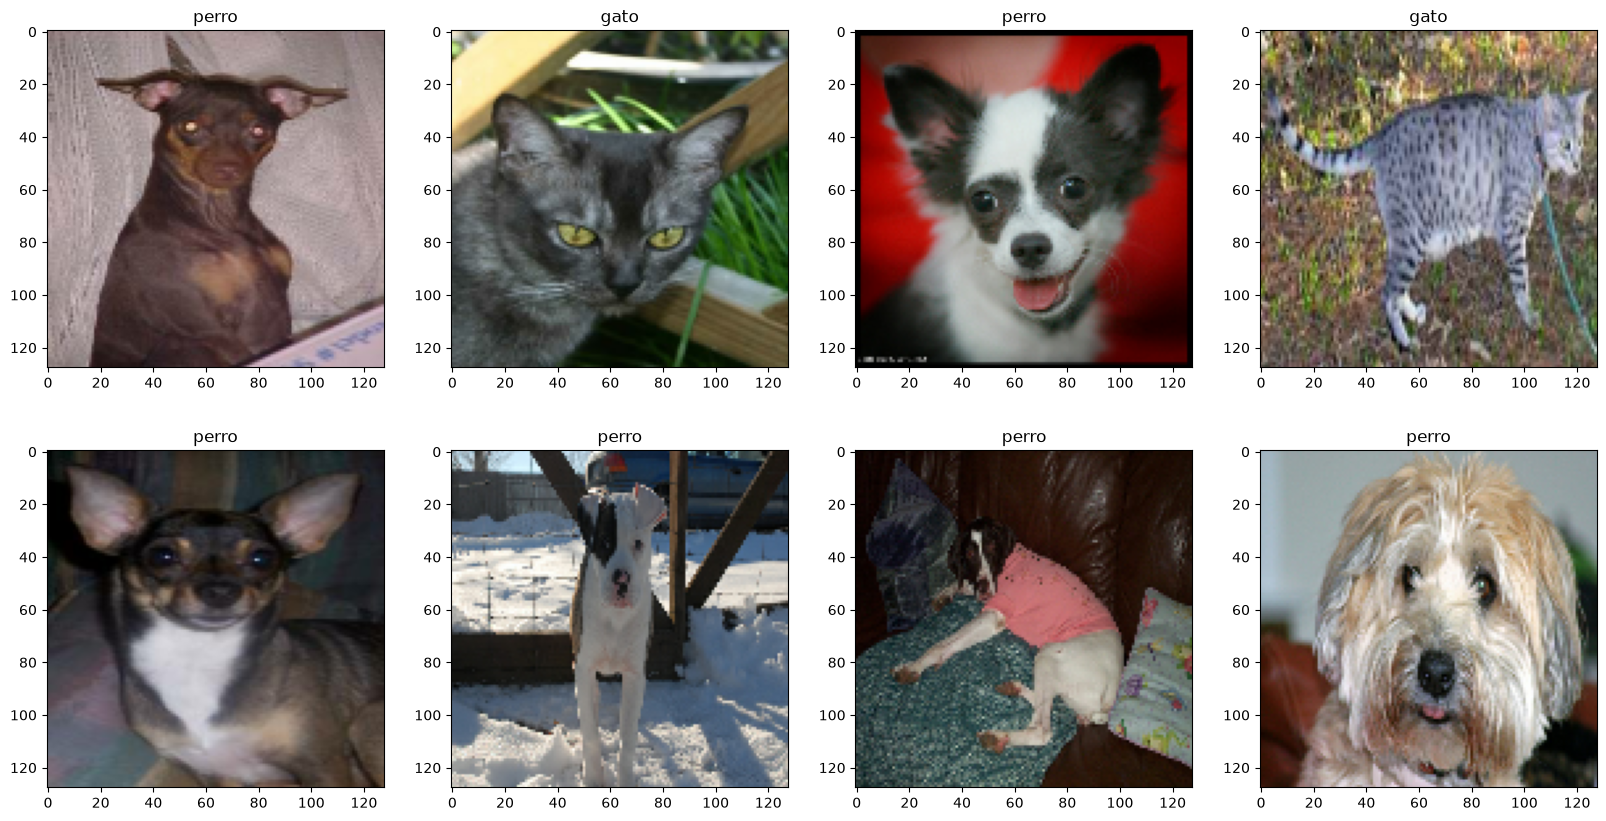

In [7]:
plt.figure(figsize=(20,10))
for i, (img, y) in enumerate(ds['train'].map(preparar).shuffle(100).take(8)):
  plt.subplot(2,4,i+1)
  plt.imshow(img)
  plt.title(NOMBRES[y])

In [ ]:
model= tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(128,128,3)),
    tf.keras.layers.RandomFlip('horizontal'),   #voltea fotos al azar 
    tf.keras.layers.RandomRotation(0.1),  #gira un poco las fotos 
    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.3),     #apaga de neuronas 
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [29]:
model.fit(train, epochs=15, validation_data= test)   #

Epoch 1/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.7815 - loss: 0.4698 - val_accuracy: 0.7814 - val_loss: 0.4695
Epoch 2/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.7818 - loss: 0.4618 - val_accuracy: 0.7967 - val_loss: 0.4283
Epoch 3/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.7837 - loss: 0.4528 - val_accuracy: 0.7863 - val_loss: 0.4481
Epoch 4/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.8008 - loss: 0.4396 - val_accuracy: 0.7948 - val_loss: 0.4336
Epoch 5/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.8016 - loss: 0.4317 - val_accuracy: 0.7999 - val_loss: 0.4228
Epoch 6/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.8082 - loss: 0.4219 - val_accuracy: 0.8005 - val_loss: 0.4292
Epoch 7/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.8027 - loss: 0.4230 - val_accuracy: 0.8029 - val_loss: 0.4134
Epoch 8/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 51ms/step - accuracy: 0.8139 - loss: 0.4015 - val_accu

In [30]:
imgs, etiquetas= next(iter(test))
probs= model.predict(imgs[:8], verbose=0).flatten()
print(etiquetas[:8])
print(probs.round().astype(int))

tf.Tensor([0 1 1 1 0 1 1 1], shape=(8,), dtype=int64)
[0 1 1 1 0 1 0 1]


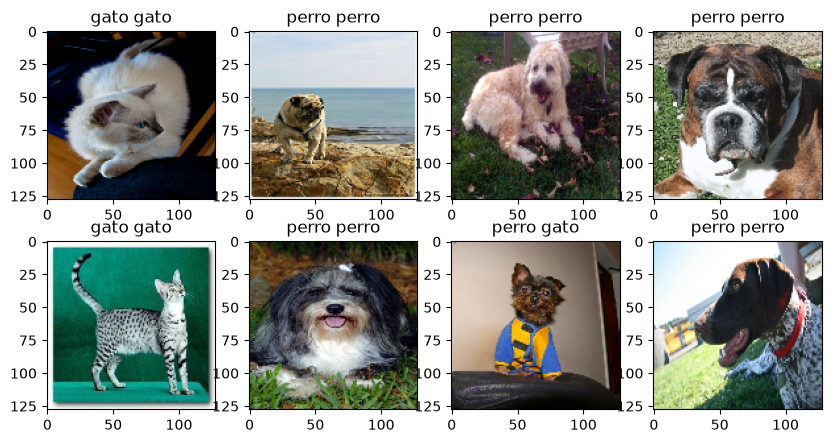

In [31]:
plt.figure(figsize=(10,5))
for i in range(8):
  plt.subplot(2,4,i+1)
  plt.imshow(imgs[i])
  plt.title(str(NOMBRES[etiquetas[i]])+ ' ' + str(NOMBRES[probs.round().astype(int)[i]]))